# Prediksi Performa Akademik Siswa Menggunakan Machine Learning
**Metode:** Gaussian Naive Bayes dan Random Forest dengan Pendekatan SMOTE

**Dataset:** [Students Performance Dataset](https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset) — Rabie El Kharoua (2024), DOI: 10.34740/KAGGLE/DS/5195702.

> **Catatan:** Dataset ini bersifat sintetis dan disediakan untuk keperluan edukasi. Hasil model bersifat *proof-of-concept*, bukan kesimpulan langsung tentang siswa nyata.

## 1. Import Library dan Konfigurasi

In [1]:
%matplotlib inline

import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from imblearn.over_sampling import SMOTE, SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    make_scorer,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
os.makedirs("output", exist_ok=True)

RANDOM_STATE = 42
CLASS_NAMES = ["A", "B", "C", "D", "F"]

print("Library berhasil di-import!")
print(f"Output directory siap: {os.path.abspath('output')}")

Library berhasil di-import!
Output directory siap: C:\Users\Zefhana Ananda\Documents\Documentss\Semester5\AI\output


## 2. Load Dataset

In [2]:
df = pd.read_csv("dataset/Student_performance_data _.csv")

print(f"Jumlah data  : {df.shape[0]} baris")
print(f"Jumlah fitur : {df.shape[1]} kolom")
print(f"\nKolom: {list(df.columns)}")
df.head(10)

Jumlah data  : 2392 baris
Jumlah fitur : 15 kolom

Kolom: ['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0
5,1006,18,0,0,1,8.191219,0,0,1,1,0,0,0,3.084184,1.0
6,1007,15,0,1,1,15.601680,10,0,3,0,1,0,0,2.748237,2.0
7,1008,15,1,1,4,15.424496,22,1,1,1,0,0,0,1.360143,4.0
8,1009,17,0,0,0,4.562008,1,0,2,0,1,0,1,2.896819,2.0
9,1010,16,1,0,1,18.444466,0,0,3,1,0,0,0,3.573474,0.0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


In [4]:
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


### 2.1 Catatan Dataset

- Dataset berisi **2.392 baris** dan **15 kolom**.
- `StudentID` adalah identitas unik dan tidak digunakan sebagai fitur.
- `GPA` **dihapus** dari fitur karena `GradeClass` diturunkan langsung dari `GPA`; memasukkannya akan menyebabkan *data leakage*.
- Dataset bersifat sintetis (El Kharoua, 2024), sehingga hasil tidak dapat digeneralisasi langsung ke populasi siswa nyata.

## 3. Exploratory Data Analysis (EDA)
### 3.1 Cek Missing Values dan Duplikat

In [5]:
print("Missing values:")
print(df.isnull().sum())
print(f"\nDuplikat: {df.duplicated().sum()}")

Missing values:
StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64

Duplikat: 0


### 3.2 Distribusi Target (GradeClass)

In [6]:
grade_labels = {
    0: "A (3.5-4.0)",
    1: "B (3.0-3.49)",
    2: "C (2.5-2.99)",
    3: "D (2.0-2.49)",
    4: "F (<2.0)",
}

print("Distribusi GradeClass (Target):")
for grade, count in df["GradeClass"].value_counts().sort_index().items():
    pct = count / len(df) * 100
    label = grade_labels.get(int(grade), "?")
    print(f"  Grade {int(grade)} - {label}: {count} siswa ({pct:.1f}%)")

Distribusi GradeClass (Target):
  Grade 0 - A (3.5-4.0): 107 siswa (4.5%)
  Grade 1 - B (3.0-3.49): 269 siswa (11.2%)
  Grade 2 - C (2.5-2.99): 391 siswa (16.3%)
  Grade 3 - D (2.0-2.49): 414 siswa (17.3%)
  Grade 4 - F (<2.0): 1211 siswa (50.6%)


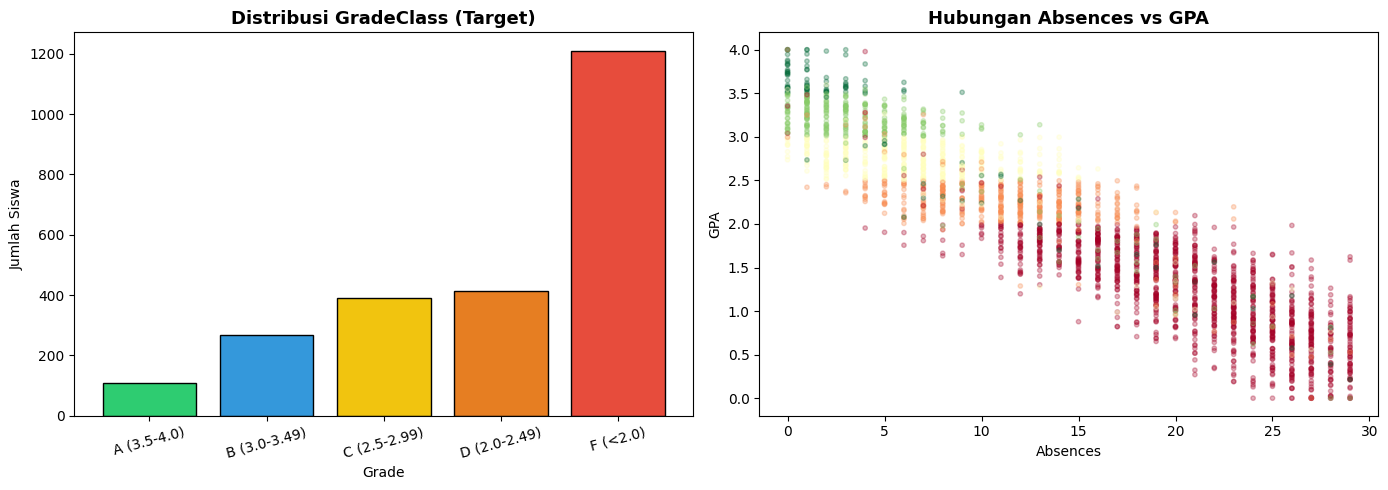

In [7]:
colors = ["#2ecc71", "#3498db", "#f1c40f", "#e67e22", "#e74c3c"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart distribusi GradeClass
grade_counts = df["GradeClass"].value_counts().sort_index()
axes[0].bar(
    [grade_labels[int(g)] for g in grade_counts.index],
    grade_counts.values,
    color=colors,
    edgecolor="black",
)
axes[0].set_title("Distribusi GradeClass (Target)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Grade")
axes[0].set_ylabel("Jumlah Siswa")
axes[0].tick_params(axis="x", rotation=15)

# Scatter: Absences vs GPA (GPA hanya untuk EDA, tidak dipakai sebagai fitur model)
axes[1].scatter(
    df["Absences"], df["GPA"],
    alpha=0.3, c=df["GradeClass"], cmap="RdYlGn_r", s=10
)
axes[1].set_title("Hubungan Absences vs GPA", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Absences")
axes[1].set_ylabel("GPA")

plt.tight_layout()
plt.savefig("output/01_eda.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.3 Heatmap Korelasi

`GPA` dan `GradeClass` ditampilkan pada heatmap hanya untuk keperluan EDA. Keduanya tidak digunakan sebagai fitur model; `GPA` dihapus karena *data leakage*.

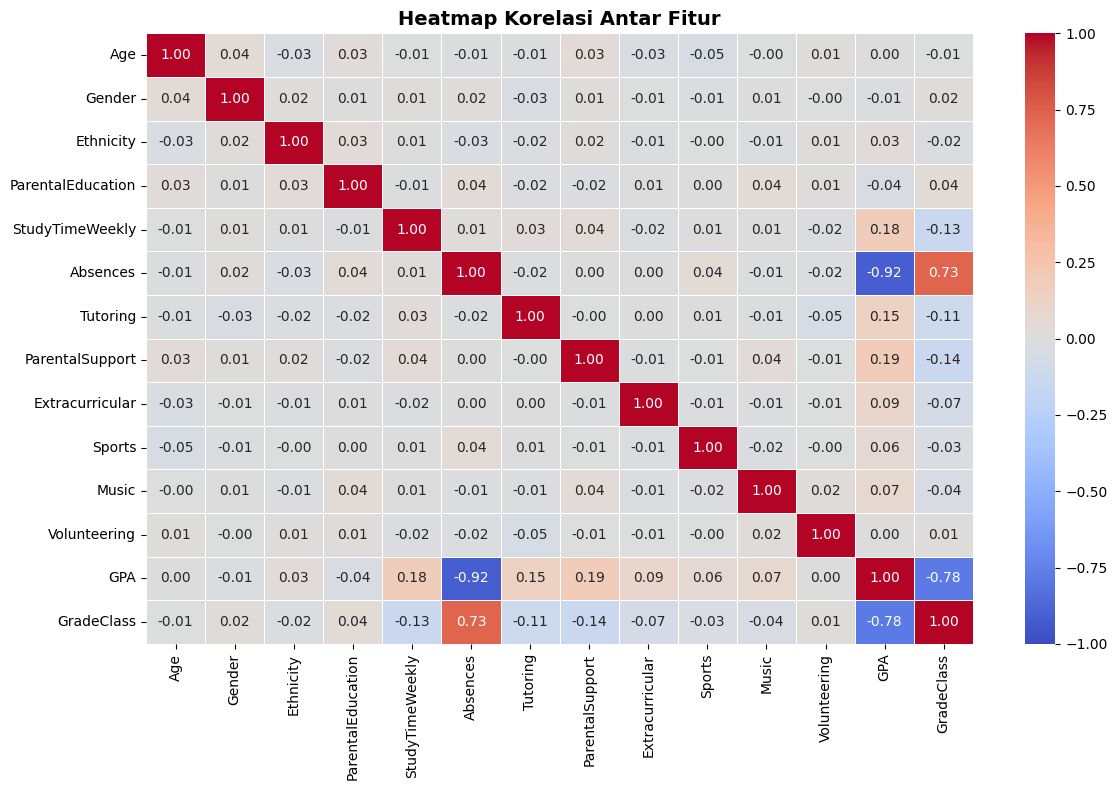

In [8]:
plt.figure(figsize=(12, 8))
numeric_cols = df.select_dtypes(include=[np.number]).columns.drop("StudentID")
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Heatmap Korelasi Antar Fitur", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("output/02_heatmap_korelasi.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Pre-processing
### 4.1 Pisahkan Fitur (X) dan Target (y)

In [9]:
# Drop StudentID (ID), GPA (bocor ke target karena GradeClass diturunkan dari GPA), dan GradeClass (target)
X = df.drop(columns=["StudentID", "GPA", "GradeClass"])
y = df["GradeClass"].astype(int)

print(f"Fitur yang digunakan ({X.shape[1]}):")
for col in X.columns:
    print(f"  - {col}")
print("\nTarget: GradeClass")

Fitur yang digunakan (12):
  - Age
  - Gender
  - Ethnicity
  - ParentalEducation
  - StudyTimeWeekly
  - Absences
  - Tutoring
  - ParentalSupport
  - Extracurricular
  - Sports
  - Music
  - Volunteering

Target: GradeClass


### 4.2 Split Data (80% Train, 20% Test, Stratified)

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Training : {X_train.shape[0]} data")
print(f"Testing  : {X_test.shape[0]} data")
print("\nDistribusi target pada data uji:")
print(y_test.value_counts().sort_index().to_string())

Training : 1913 data
Testing  : 479 data

Distribusi target pada data uji:
GradeClass
0     21
1     54
2     78
3     83
4    243


### 4.3 Standardisasi Fitur

`StandardScaler` di-fit hanya pada data latih. Gaussian Naive Bayes dan Random Forest relatif tidak sensitif terhadap skala fitur; standardisasi terutama dilakukan agar perhitungan jarak Euclidean pada SMOTE tidak didominasi fitur berskala besar.

In [11]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("StandardScaler berhasil diterapkan!")
print("\nContoh data SEBELUM scaling (5 baris pertama):")
print(X_train.head())
print("\nContoh data SESUDAH scaling (5 baris pertama):")
print(pd.DataFrame(X_train_scaled[:5], columns=X.columns))

StandardScaler berhasil diterapkan!

Contoh data SEBELUM scaling (5 baris pertama):
      Age  Gender  Ethnicity  ParentalEducation  StudyTimeWeekly  Absences  \
653    15       0          2                  3         1.901131         7   
200    17       0          1                  2        10.546218        18   
1606   16       1          1                  0         6.177218        27   
1032   15       0          2                  1         6.108270        24   
1293   15       1          1                  2         0.305297        23   

      Tutoring  ParentalSupport  Extracurricular  Sports  Music  Volunteering  
653          0                2                0       0      0             0  
200          0                1                0       0      1             0  
1606         0                1                0       1      0             0  
1032         1                3                1       0      1             0  
1293         0                0                

### 4.4 SMOTE pada Data Latih

SMOTE hanya diterapkan pada data latih. Data uji **tidak** di-resample agar evaluasi tetap mencerminkan distribusi kelas yang tidak seimbang.

In [12]:
print("Distribusi SEBELUM SMOTE:")
for grade, count in pd.Series(y_train).value_counts().sort_index().items():
    print(f"  Grade {grade}: {count}")

smote = SMOTE(random_state=RANDOM_STATE)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

print(f"\nDistribusi SESUDAH SMOTE (total {len(y_train_resampled)} sampel):")
for grade, count in pd.Series(y_train_resampled).value_counts().sort_index().items():
    print(f"  Grade {grade}: {count}")

Distribusi SEBELUM SMOTE:
  Grade 0: 86
  Grade 1: 215
  Grade 2: 313
  Grade 3: 331
  Grade 4: 968

Distribusi SESUDAH SMOTE (total 4840 sampel):
  Grade 0: 968
  Grade 1: 968
  Grade 2: 968
  Grade 3: 968
  Grade 4: 968


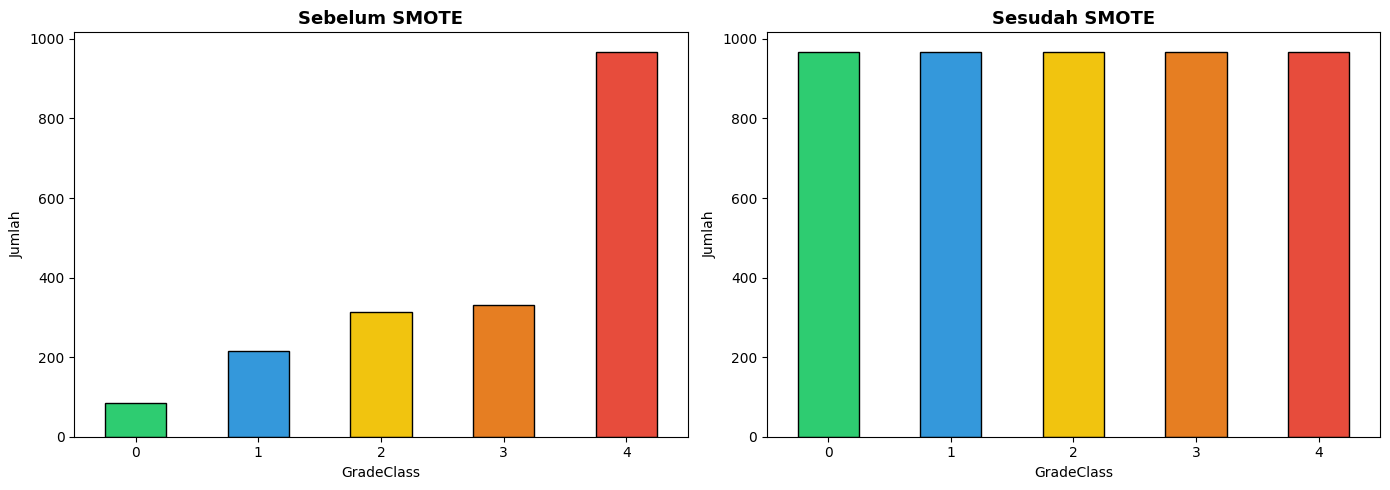

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

pd.Series(y_train).value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color=colors, edgecolor="black"
)
axes[0].set_title("Sebelum SMOTE", fontsize=13, fontweight="bold")
axes[0].set_xlabel("GradeClass")
axes[0].set_ylabel("Jumlah")
axes[0].tick_params(axis="x", rotation=0)

pd.Series(y_train_resampled).value_counts().sort_index().plot(
    kind="bar", ax=axes[1], color=colors, edgecolor="black"
)
axes[1].set_title("Sesudah SMOTE", fontsize=13, fontweight="bold")
axes[1].set_xlabel("GradeClass")
axes[1].set_ylabel("Jumlah")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig("output/03_smote_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Training dan Evaluasi Model
### 5.1 Fungsi Evaluasi

In [14]:
def compute_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro_F1": f1_score(y_true, y_pred, average="macro"),
        "Recall_F": recall_score(y_true, y_pred, labels=[4], average="macro", zero_division=0),
        "Recall_A": recall_score(y_true, y_pred, labels=[0], average="macro", zero_division=0),
    }


def evaluate_model(name, model, X_tr, y_tr, X_te, y_te, verbose=True):
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    metrics = compute_metrics(y_te, pred)

    if verbose:
        print(f"=== {name} ===")
        print(f"Akurasi  : {metrics['Accuracy']:.4f} ({metrics['Accuracy'] * 100:.2f}%)")
        print(f"Macro-F1 : {metrics['Macro_F1']:.4f}")
        print(f"Recall F : {metrics['Recall_F']:.4f}")
        print(f"Recall A : {metrics['Recall_A']:.4f}")
        print("\nClassification Report:")
        print(classification_report(y_te, pred, target_names=CLASS_NAMES))

    return {"Model": name, **metrics}, pred, model

### 5.2 Model 1: Gaussian Naive Bayes (dengan SMOTE)

In [15]:
nb_result, nb_pred, nb_model = evaluate_model(
    "Naive Bayes",
    GaussianNB(),
    X_train_resampled,
    y_train_resampled,
    X_test_scaled,
    y_test,
)

=== Naive Bayes ===
Akurasi  : 0.6159 (61.59%)
Macro-F1 : 0.4595
Recall F : 0.7984
Recall A : 0.2381

Classification Report:
              precision    recall  f1-score   support

           A       0.14      0.24      0.17        21
           B       0.33      0.39      0.36        54
           C       0.49      0.50      0.49        78
           D       0.39      0.43      0.41        83
           F       0.94      0.80      0.86       243

    accuracy                           0.62       479
   macro avg       0.46      0.47      0.46       479
weighted avg       0.67      0.62      0.64       479



### 5.3 Model 2: Random Forest (dengan SMOTE)

In [16]:
rf_result, rf_pred, rf_model = evaluate_model(
    "Random Forest",
    RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    X_train_resampled,
    y_train_resampled,
    X_test_scaled,
    y_test,
)

=== Random Forest ===
Akurasi  : 0.6889 (68.89%)
Macro-F1 : 0.5247
Recall F : 0.8848
Recall A : 0.1905

Classification Report:
              precision    recall  f1-score   support

           A       0.24      0.19      0.21        21
           B       0.57      0.46      0.51        54
           C       0.50      0.55      0.52        78
           D       0.45      0.52      0.48        83
           F       0.91      0.88      0.90       243

    accuracy                           0.69       479
   macro avg       0.53      0.52      0.52       479
weighted avg       0.70      0.69      0.69       479



### 5.4 Perbandingan Metrik

In [17]:
results_df = pd.DataFrame([nb_result, rf_result])[["Model", "Accuracy", "Macro_F1", "Recall_F", "Recall_A"]]
print("Perbandingan model pada data uji:")
print(results_df.to_string(index=False))
print(f"\nSelisih akurasi RF - NB : {(rf_result['Accuracy'] - nb_result['Accuracy']) * 100:.2f} poin persentase")
print(f"Selisih macro-F1 RF - NB: {rf_result['Macro_F1'] - nb_result['Macro_F1']:.4f}")
results_df

Perbandingan model pada data uji:
        Model  Accuracy  Macro_F1  Recall_F  Recall_A
  Naive Bayes  0.615866  0.459518  0.798354  0.238095
Random Forest  0.688935  0.524654  0.884774  0.190476

Selisih akurasi RF - NB : 7.31 poin persentase
Selisih macro-F1 RF - NB: 0.0651


,Model,Accuracy,Macro_F1,Recall_F,Recall_A
0,Naive Bayes,0.615866,0.459518,0.798354,0.238095
1,Random Forest,0.688935,0.524654,0.884774,0.190476


### 5.5 Confusion Matrix

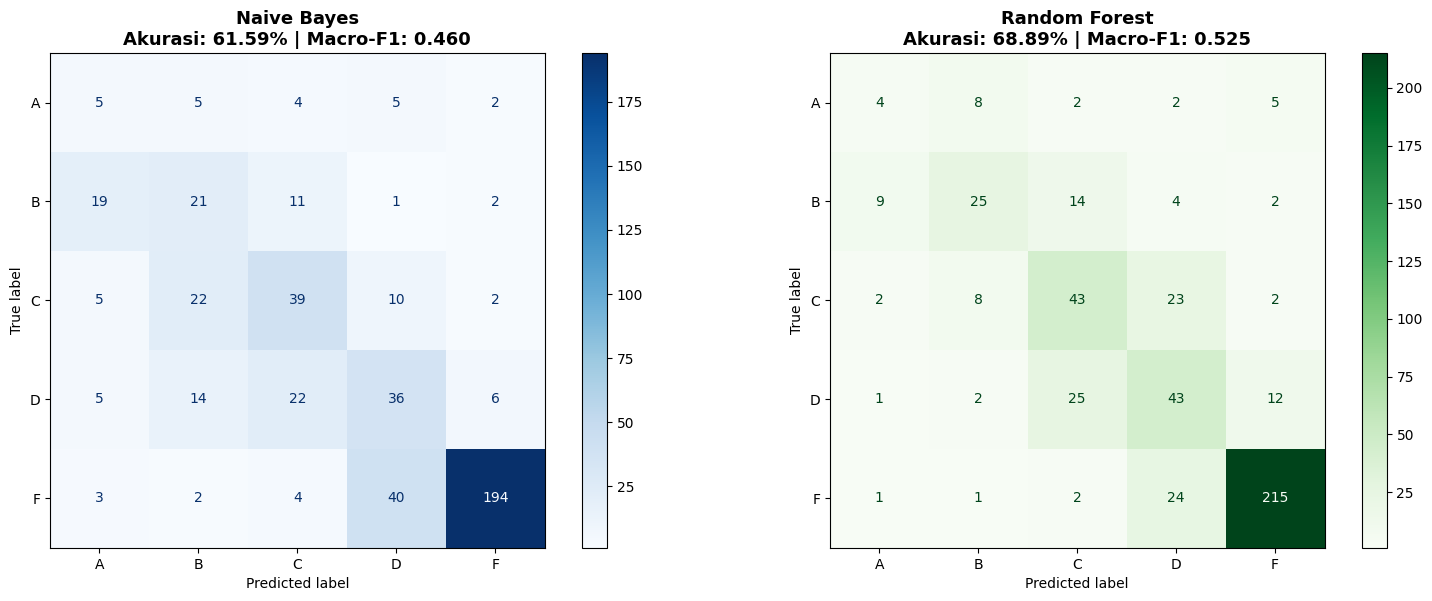

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test, nb_pred, display_labels=CLASS_NAMES, cmap="Blues", ax=axes[0]
)
axes[0].set_title(
    f"Naive Bayes\nAkurasi: {nb_result['Accuracy']:.2%} | Macro-F1: {nb_result['Macro_F1']:.3f}",
    fontsize=13,
    fontweight="bold",
)

ConfusionMatrixDisplay.from_predictions(
    y_test, rf_pred, display_labels=CLASS_NAMES, cmap="Greens", ax=axes[1]
)
axes[1].set_title(
    f"Random Forest\nAkurasi: {rf_result['Accuracy']:.2%} | Macro-F1: {rf_result['Macro_F1']:.3f}",
    fontsize=13,
    fontweight="bold",
)

plt.tight_layout()
plt.savefig("output/04_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.6 Perbandingan Metrik Visual

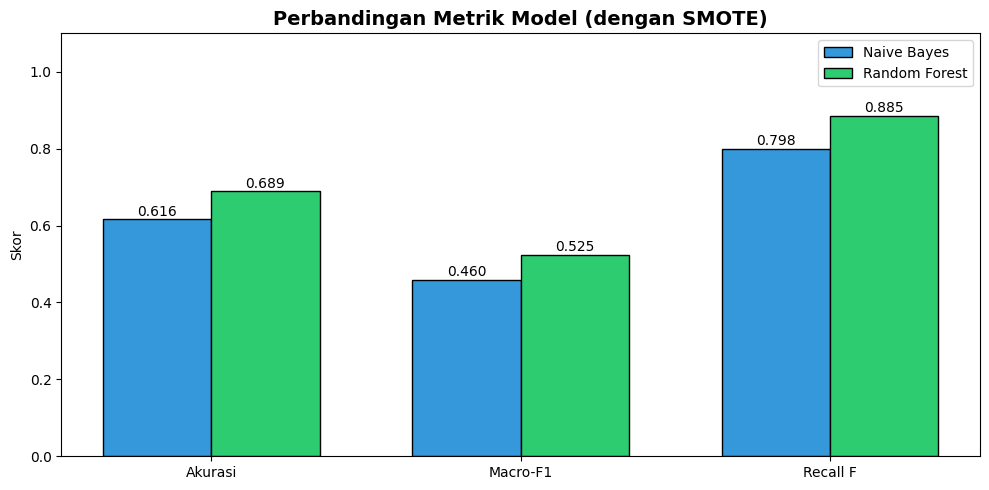

In [19]:
metrics_to_plot = ["Accuracy", "Macro_F1", "Recall_F"]
labels_to_plot = ["Akurasi", "Macro-F1", "Recall F"]

x = np.arange(len(metrics_to_plot))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
nb_values = [nb_result[m] for m in metrics_to_plot]
rf_values = [rf_result[m] for m in metrics_to_plot]

bars_nb = ax.bar(
    x - width / 2, nb_values, width,
    label="Naive Bayes", color="#3498db", edgecolor="black"
)
bars_rf = ax.bar(
    x + width / 2, rf_values, width,
    label="Random Forest", color="#2ecc71", edgecolor="black"
)

for bars in (bars_nb, bars_rf):
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.01,
            f"{height:.3f}",
            ha="center",
            fontsize=10,
        )

ax.set_xticks(x)
ax.set_xticklabels(labels_to_plot)
ax.set_ylim(0, 1.1)
ax.set_ylabel("Skor")
ax.set_title("Perbandingan Metrik Model (dengan SMOTE)", fontsize=14, fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig("output/05_perbandingan_metrik.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.7 Feature Importance (Random Forest)

In [20]:
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

print("Feature Importance (Random Forest):")
for i, (feat, imp) in enumerate(importances.items(), 1):
    print(f"  {i:2d}. {feat:25s}: {imp:.4f}")

Feature Importance (Random Forest):
   1. Absences                 : 0.3442
   2. StudyTimeWeekly          : 0.1278
   3. ParentalSupport          : 0.1073
   4. ParentalEducation        : 0.0775
   5. Age                      : 0.0767
   6. Ethnicity                : 0.0689
   7. Gender                   : 0.0395
   8. Extracurricular          : 0.0392
   9. Sports                   : 0.0357
  10. Tutoring                 : 0.0350
  11. Music                    : 0.0264
  12. Volunteering             : 0.0218


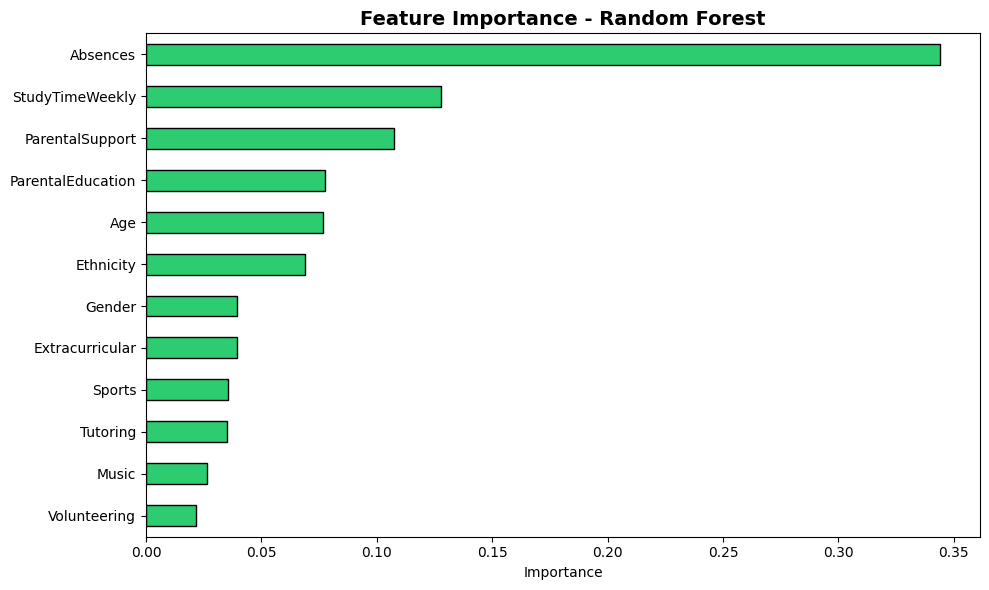

In [21]:
plt.figure(figsize=(10, 6))
importances.plot(kind="barh", color="#2ecc71", edgecolor="black")
plt.title("Feature Importance - Random Forest", fontsize=14, fontweight="bold")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("output/06_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.8 Catatan Interpretasi

- Feature importance menunjukkan kontribusi prediktif pada model Random Forest, **bukan hubungan kausal**.
- `Absences` menjadi fitur paling dominan, diikuti `StudyTimeWeekly` dan `ParentalSupport`.
- Karena dataset sintetis, interpretasi ini tidak dapat langsung dijadikan rekomendasi kebijakan nyata.

## 6. Analisis Tambahan: Baseline, Ablation Resampling, dan Validasi Silang
### 6.1 Baseline Majority

In [22]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_result = {"Model": "Baseline (mayoritas F)", **compute_metrics(y_test, baseline_pred)}
print(pd.DataFrame([baseline_result]).to_string(index=False))

                 Model  Accuracy  Macro_F1  Recall_F  Recall_A
Baseline (mayoritas F)  0.507307  0.134626       1.0       0.0


### 6.2 Ablation: Tanpa SMOTE vs SMOTE

Ablation menggunakan split dan model yang sama; hanya penggunaan SMOTE yang dibedakan. Tujuannya menguji apakah penyeimbangan data benar-benar memberikan perbaikan.

In [23]:
ablation_rows = []

model_factories = {
    "Naive Bayes": GaussianNB,
    "Random Forest": lambda: RandomForestClassifier(
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
    ),
}

for name, factory in model_factories.items():
    for use_smote in [False, True]:
        model = factory()
        if use_smote:
            model.fit(X_train_resampled, y_train_resampled)
        else:
            model.fit(X_train_scaled, y_train)

        pred = model.predict(X_test_scaled)
        ablation_rows.append({
            "Model": name,
            "Skenario": "SMOTE" if use_smote else "Tanpa SMOTE",
            **compute_metrics(y_test, pred),
        })

ablation_df = pd.DataFrame(ablation_rows)[
    ["Model", "Skenario", "Accuracy", "Macro_F1", "Recall_F", "Recall_A"]
]
print(ablation_df.to_string(index=False))

        Model    Skenario  Accuracy  Macro_F1  Recall_F  Recall_A
  Naive Bayes Tanpa SMOTE  0.672234  0.443283  0.925926  0.047619
  Naive Bayes       SMOTE  0.615866  0.459518  0.798354  0.238095
Random Forest Tanpa SMOTE  0.722338  0.556803  0.913580  0.190476
Random Forest       SMOTE  0.688935  0.524654  0.884774  0.190476


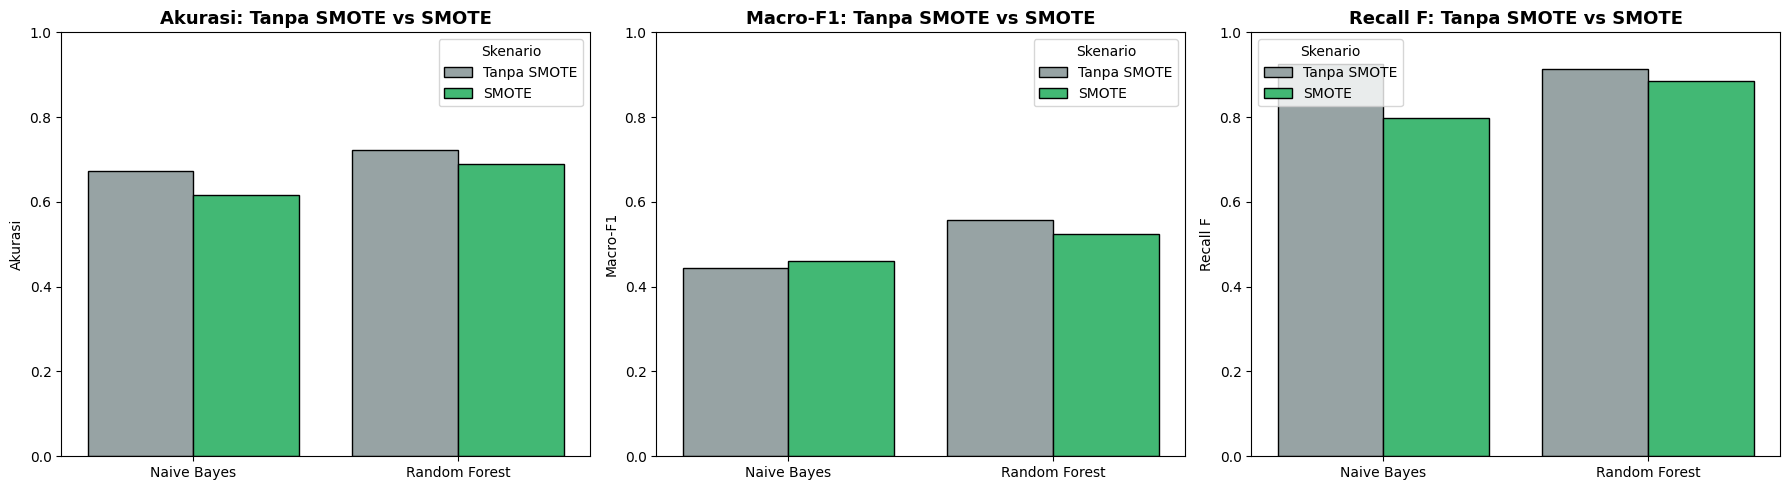

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metric, title in zip(
    axes,
    ["Accuracy", "Macro_F1", "Recall_F"],
    ["Akurasi", "Macro-F1", "Recall F"],
):
    sns.barplot(
        data=ablation_df,
        x="Model",
        y=metric,
        hue="Skenario",
        hue_order=["Tanpa SMOTE", "SMOTE"],
        palette=["#95a5a6", "#2ecc71"],
        edgecolor="black",
        ax=ax,
    )
    ax.set_title(f"{title}: Tanpa SMOTE vs SMOTE", fontsize=13, fontweight="bold")
    ax.set_ylim(0, 1.0)
    ax.set_xlabel("")
    ax.set_ylabel(title)

plt.tight_layout()
plt.savefig("output/07_ablation_smote.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.3 Ablation: SMOTENC (Fitur Kategorikal Ditangani Benar)

SMOTE biasa menginterpolasi seluruh fitur, termasuk fitur kategorikal yang telah dikodekan sebagai bilangan bulat. SMOTENC memisahkan kedua jenis fitur: fitur numerik diinterpolasi, sedangkan fitur kategorikal dipilih dari nilai kategori yang ada.

Pada eksperimen ini, `StandardScaler` hanya diterapkan pada fitur numerik (`Age`, `StudyTimeWeekly`, `Absences`). Fitur kategorikal (`Gender`, `Ethnicity`, `ParentalEducation`, `Tutoring`, `ParentalSupport`, `Extracurricular`, `Sports`, `Music`, `Volunteering`) dilewatkan tanpa scaling, lalu SMOTENC diterapkan pada data latih.

In [25]:
categorical_cols = [
    "Gender",
    "Ethnicity",
    "ParentalEducation",
    "Tutoring",
    "ParentalSupport",
    "Extracurricular",
    "Sports",
    "Music",
    "Volunteering",
]
numeric_cols = [col for col in X.columns if col not in categorical_cols]
smotenc_mask = [False] * len(numeric_cols) + [True] * len(categorical_cols)

print("Fitur numerik    :", numeric_cols)
print("Fitur kategorikal:", categorical_cols)

smotenc_rows = []
smotenc_preds = {}
for name, factory in model_factories.items():
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numeric_cols),
            ("cat", "passthrough", categorical_cols),
        ]
    )
    smotenc_pipeline = ImbPipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("smotenc", SMOTENC(categorical_features=smotenc_mask, random_state=RANDOM_STATE)),
            ("model", factory()),
        ]
    )
    smotenc_pipeline.fit(X_train, y_train)
    pred = smotenc_pipeline.predict(X_test)
    smotenc_preds[name] = pred
    smotenc_rows.append({
        "Model": name,
        "Skenario": "SMOTENC",
        **compute_metrics(y_test, pred),
    })

smotenc_df = pd.DataFrame(smotenc_rows)[
    ["Model", "Skenario", "Accuracy", "Macro_F1", "Recall_F", "Recall_A"]
]
print("Evaluasi SMOTENC pada data uji:")
print(smotenc_df.to_string(index=False))

Fitur numerik    : ['Age', 'StudyTimeWeekly', 'Absences']
Fitur kategorikal: ['Gender', 'Ethnicity', 'ParentalEducation', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering']


Evaluasi SMOTENC pada data uji:
        Model Skenario  Accuracy  Macro_F1  Recall_F  Recall_A
  Naive Bayes  SMOTENC  0.553236  0.395580  0.765432  0.285714
Random Forest  SMOTENC  0.670146  0.521678  0.839506  0.238095


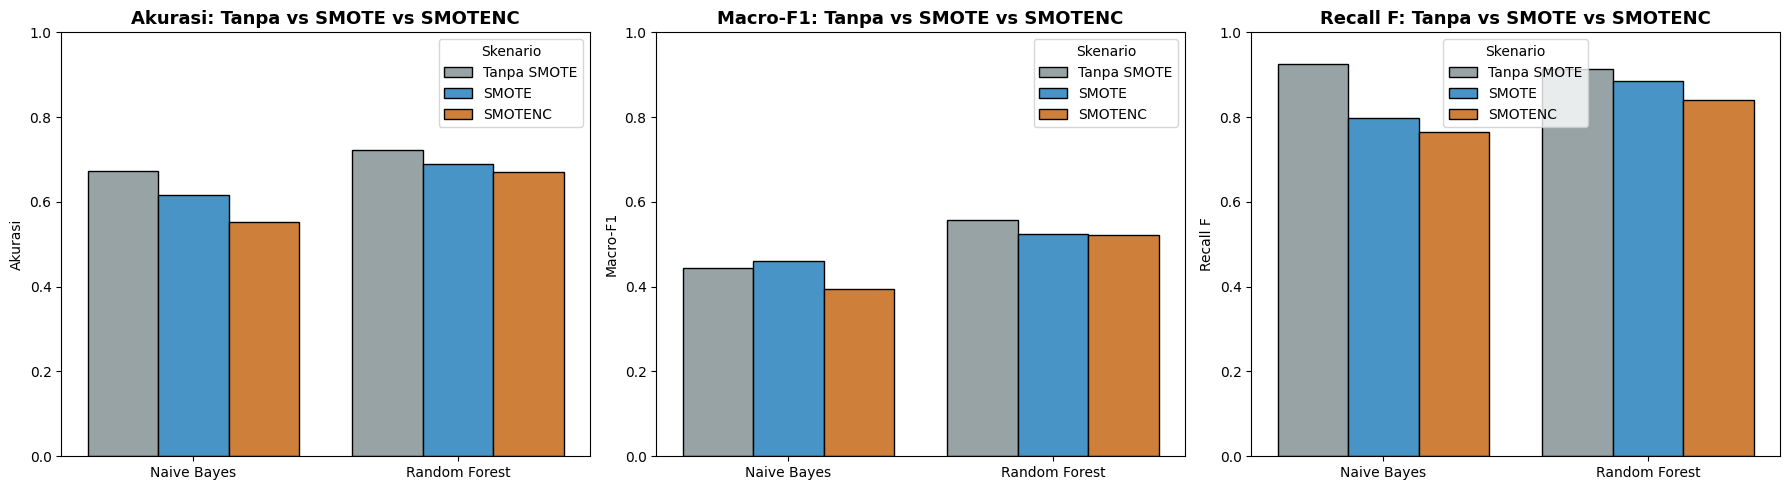

In [26]:
all_resampling_df = pd.concat([ablation_df, smotenc_df], ignore_index=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metric, title in zip(
    axes,
    ["Accuracy", "Macro_F1", "Recall_F"],
    ["Akurasi", "Macro-F1", "Recall F"],
):
    sns.barplot(
        data=all_resampling_df,
        x="Model",
        y=metric,
        hue="Skenario",
        hue_order=["Tanpa SMOTE", "SMOTE", "SMOTENC"],
        palette=["#95a5a6", "#3498db", "#e67e22"],
        edgecolor="black",
        ax=ax,
    )
    ax.set_title(f"{title}: Tanpa vs SMOTE vs SMOTENC", fontsize=13, fontweight="bold")
    ax.set_ylim(0, 1.0)
    ax.set_xlabel("")
    ax.set_ylabel(title)

plt.tight_layout()
plt.savefig("output/09_ablation_smotenc.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.4 Validasi Silang 5-Fold

Validasi silang menggunakan pipeline agar `StandardScaler` dan resampling (SMOTE/SMOTENC) hanya diterapkan pada data latih di setiap fold. Dengan demikian, tidak ada kebocoran data dari fold uji. SMOTENC memakai `ColumnTransformer` agar hanya fitur numerik yang diskalakan.

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "recall_f": make_scorer(recall_score, labels=[4], average="macro", zero_division=0),
}

scenario_names = ["Tanpa SMOTE", "SMOTE", "SMOTENC"]
cv_rows = []
for name, factory in model_factories.items():
    for scenario in scenario_names:
        if scenario == "SMOTENC":
            preprocessor = ColumnTransformer(
                transformers=[
                    ("num", StandardScaler(), numeric_cols),
                    ("cat", "passthrough", categorical_cols),
                ]
            )
            steps = [
                ("preprocessor", preprocessor),
                ("smotenc", SMOTENC(categorical_features=smotenc_mask, random_state=RANDOM_STATE)),
                ("model", factory()),
            ]
        else:
            steps = [("scaler", StandardScaler())]
            if scenario == "SMOTE":
                steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
            steps.append(("model", factory()))

        pipeline = ImbPipeline(steps)
        scores = cross_validate(
            pipeline, X, y,
            cv=cv, scoring=scoring, n_jobs=1, error_score="raise"
        )

        cv_rows.append({
            "Model": name,
            "Skenario": scenario,
            "Accuracy": scores["test_accuracy"].mean(),
            "Accuracy_std": scores["test_accuracy"].std(),
            "Macro_F1": scores["test_macro_f1"].mean(),
            "Macro_F1_std": scores["test_macro_f1"].std(),
            "Recall_F": scores["test_recall_f"].mean(),
            "Recall_F_std": scores["test_recall_f"].std(),
        })

cv_df = pd.DataFrame(cv_rows)
cv_df_display = cv_df.copy()
for col in ["Accuracy", "Accuracy_std", "Macro_F1", "Macro_F1_std", "Recall_F", "Recall_F_std"]:
    cv_df_display[col] = cv_df_display[col].map(lambda v: f"{v:.3f}")
print(cv_df_display.to_string(index=False))

        Model    Skenario Accuracy Accuracy_std Macro_F1 Macro_F1_std Recall_F Recall_F_std
  Naive Bayes Tanpa SMOTE    0.660        0.015    0.441        0.019    0.912        0.018
  Naive Bayes       SMOTE    0.610        0.028    0.471        0.038    0.794        0.014
  Naive Bayes     SMOTENC    0.530        0.053    0.393        0.041    0.738        0.053
Random Forest Tanpa SMOTE    0.714        0.013    0.545        0.032    0.929        0.018
Random Forest       SMOTE    0.696        0.017    0.543        0.036    0.902        0.013
Random Forest     SMOTENC    0.676        0.011    0.523        0.019    0.881        0.022


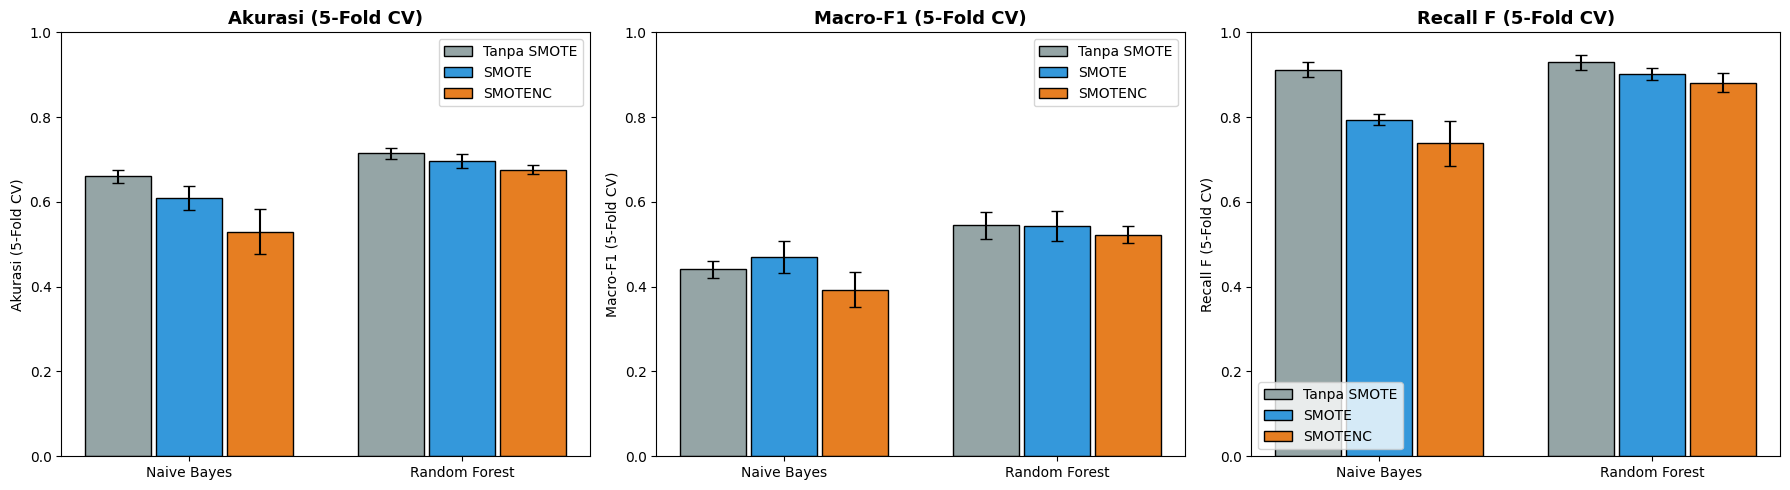

In [28]:
models = ["Naive Bayes", "Random Forest"]
scenario_names = ["Tanpa SMOTE", "SMOTE", "SMOTENC"]
bar_colors = ["#95a5a6", "#3498db", "#e67e22"]
x = np.arange(len(models))
width = 0.24
offset = 0.26

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metric, title in zip(
    axes,
    ["Accuracy", "Macro_F1", "Recall_F"],
    ["Akurasi (5-Fold CV)", "Macro-F1 (5-Fold CV)", "Recall F (5-Fold CV)"],
):
    for i, scenario in enumerate(scenario_names):
        subset = (
            cv_df[cv_df["Skenario"] == scenario]
            .set_index("Model")
            .loc[models]
        )
        ax.bar(
            x + (i - 1) * offset,
            subset[metric],
            width,
            yerr=subset[f"{metric}_std"],
            capsize=4,
            label=scenario,
            color=bar_colors[i],
            edgecolor="black",
        )
    ax.set_xticks(x)
    ax.set_xticklabels(models)
    ax.set_ylim(0, 1.0)
    ax.set_ylabel(title)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.legend()

plt.tight_layout()
plt.savefig("output/08_cv_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.5 Ringkasan Temuan

**Evaluasi pada satu split 80/20:**

| Skenario | Model | Accuracy | Macro-F1 | Recall F | Recall A |
|---|---|---:|---:|---:|---:|
| Tanpa SMOTE | Naive Bayes | 67.22% | 0.443 | 0.926 | 0.048 |
| Tanpa SMOTE | Random Forest | 72.23% | 0.557 | 0.914 | 0.190 |
| SMOTE | Naive Bayes | 61.59% | 0.460 | 0.798 | 0.238 |
| SMOTE | Random Forest | 68.89% | 0.525 | 0.885 | 0.190 |
| SMOTENC | Naive Bayes | 55.32% | 0.396 | 0.765 | 0.286 |
| SMOTENC | Random Forest | 67.01% | 0.522 | 0.840 | 0.238 |

**Validasi silang 5-fold (mean ± std):**

| Model | Skenario | Accuracy | Macro-F1 | Recall F |
|---|---|---:|---:|---:|
| Naive Bayes | Tanpa SMOTE | 0.660 ± 0.015 | 0.441 ± 0.019 | 0.912 ± 0.018 |
| Naive Bayes | SMOTE | 0.610 ± 0.028 | 0.471 ± 0.038 | 0.794 ± 0.014 |
| Naive Bayes | SMOTENC | 0.530 ± 0.053 | 0.393 ± 0.041 | 0.738 ± 0.053 |
| Random Forest | Tanpa SMOTE | 0.714 ± 0.013 | 0.545 ± 0.032 | 0.929 ± 0.018 |
| Random Forest | SMOTE | 0.696 ± 0.017 | 0.543 ± 0.036 | 0.902 ± 0.013 |
| Random Forest | SMOTENC | 0.676 ± 0.011 | 0.523 ± 0.019 | 0.881 ± 0.022 |

**Interpretasi:**

- Random Forest tetap model terbaik dari sisi akurasi dan macro-F1 pada semua skenario resampling.
- Tanpa SMOTE memberikan recall F tertinggi untuk kedua model. Ini penting untuk konteks *early warning* siswa berisiko gagal.
- SMOTE meningkatkan recall kelas A pada Naive Bayes (4,8% menjadi 23,8%), tetapi menurunkan recall kelas F (92,6% menjadi 79,8%).
- SMOTENC, yang menangani fitur kategorikal dengan lebih tepat, tidak meningkatkan akurasi atau macro-F1. Recall A naik lebih tinggi (Naive Bayes 28,6%; Random Forest 23,8%), tetapi recall F turun (Naive Bayes 76,5%; Random Forest 84,0%). Dengan kata lain, penanganan kategorikal yang lebih benar menggeser kesalahan ke kelas A, bukan menghilangkannya.
- Pola pada validasi silang konsisten: tanpa resampling memiliki recall F tertinggi; SMOTE memberi macro-F1 Naive Bayes lebih baik; SMOTENC tidak memberi perbaikan menyeluruh.
- SMOTE dan SMOTENC bukan perbaikan tanpa biaya. Efeknya bergantung pada tujuan evaluasi; untuk keseimbangan antar-kelas, macro-F1 lebih tepat daripada akurasi, sedangkan untuk *early warning* F, recall F lebih relevan.
- Kelas A dan B masih sulit diprediksi (F1 kelas A sekitar 0,17-0,21), sehingga model belum layak digunakan sebagai satu-satunya dasar intervensi.

## 7. Kesimpulan

1. **Random Forest mengungguli Gaussian Naive Bayes** pada data uji, baik dari akurasi maupun macro-F1, pada semua skenario resampling.
2. **SMOTE pada data latih** meningkatkan recall kelas minoritas A untuk Naive Bayes, tetapi menurunkan akurasi dan recall kelas F. Untuk Random Forest, SMOTE tidak meningkatkan akurasi maupun macro-F1 secara berarti.
3. **SMOTENC**, yang menangani fitur kategorikal dengan lebih tepat, juga tidak meningkatkan akurasi atau macro-F1. SMOTENC menaikkan recall A (Naive Bayes 28,6%; Random Forest 23,8%), tetapi menurunkan recall F (Naive Bayes 76,5%; Random Forest 84,0%).
4. Untuk konteks **early warning siswa berisiko gagal**, recall kelas F perlu menjadi perhatian utama; pada eksperimen ini model tanpa resampling memberikan recall F tertinggi.
5. Fitur paling dominan menurut Random Forest adalah **Absences**, diikuti **StudyTimeWeekly** dan **ParentalSupport**. Feature importance bersifat prediktif, bukan kausal.
6. **Keterbatasan:** dataset sintetis, performa kelas A/B masih rendah, hyperparameter belum dioptimalkan, dan hasil bergantung pada satu split utama meskipun sudah diperiksa dengan validasi silang. SMOTE dan SMOTENC telah diuji, tetapi bukan solusi otomatis untuk ketidakseimbangan kelas.
7. **Penelitian lanjutan** dapat mempertimbangkan class weighting, threshold tuning, target biner F vs non-F, hyperparameter tuning, dan validasi pada data nyata.

### Catatan metodologis

- Hasil evaluasi utama menggunakan **satu split 80/20** dengan `random_state=42`; validasi silang 5-fold digunakan untuk memeriksa kestabilan pola.
- Perbedaan performa antara tanpa resampling, SMOTE, dan SMOTENC menunjukkan bahwa penyeimbangan data perlu dievaluasi dengan metrik yang sesuai dengan tujuan, bukan hanya akurasi.
- Sitasi dataset: El Kharoua, R. (2024). *Students Performance Dataset*. Kaggle. https://doi.org/10.34740/KAGGLE/DS/5195702

## 8. Referensi

- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5-32.
- Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic minority over-sampling technique. *Journal of Artificial Intelligence Research*, 16, 321-357.
- El Kharoua, R. (2024). *Students Performance Dataset*. Kaggle. https://doi.org/10.34740/KAGGLE/DS/5195702
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.
- Rish, I. (2001). An empirical study of the naive Bayes classifier. *IJCAI 2001 Workshop on Empirical Methods in Artificial Intelligence*, 3(22), 41-46.